
# Telco Customer Churn — Model Benchmarking

## Objective

This notebook benchmarks multiple classification models for predicting customer churn.

The objectives are:
- Compare Logistic Regression, Random Forest, Gradient Boosting, and XGBoost.
- Evaluate different class imbalance strategies.
- Use consistent stratified 5-fold cross-validation.
- Evaluate Average Precision, ROC-AUC, Precision, Recall, F1, and Balanced Accuracy.
- Measure training and prediction times.
- Identify promising candidates for hyperparameter optimization.

The held-out test set is not used during model benchmarking.


In [1]:

from pathlib import Path
import sys

import pandas as pd

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline

from xgboost import XGBClassifier


from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler


# Project root
project_root = Path.cwd().resolve()

if project_root.name == "notebooks":
    project_root = project_root.parent

sys.path.insert(0, str(project_root))

from src.preprocessing import clean_telco_data, build_preprocessor
from src.modeling import evaluate_model_cv
from src.modeling import compare_models_cv



# Load and clean data
data_path = (
    project_root / "data" / "raw"
    / "WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

df = pd.read_csv(data_path)
df = clean_telco_data(df)

# Reproduce the original train/test split
train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["Churn"]
)

X_train = train_df.drop(columns=["customerID", "Churn"])
y_train = train_df["Churn"].map({"No": 0, "Yes": 1})

X_test = test_df.drop(columns=["customerID", "Churn"])
y_test = test_df["Churn"].map({"No": 0, "Yes": 1})

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Training churn rate:", round(y_train.mean(), 4))


Training shape: (5634, 19)
Test shape: (1409, 19)
Training churn rate: 0.2654


In [2]:

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

numeric_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

binary_features = ["SeniorCitizen"]

categorical_features = [
    col for col in X_train.columns
    if col not in numeric_features + binary_features
]

print("Numerical:", len(numeric_features))
print("Categorical:", len(categorical_features))
print("Binary:", len(binary_features))


Numerical: 3
Categorical: 15
Binary: 1



## 1. Logistic Regression

### 1.1 Standard Logistic Regression

Logistic Regression is used as the first baseline classification model.

This configuration:
- Uses the preprocessing pipeline developed in feature engineering.
- Applies no class weighting or resampling.
- Uses the default L2 regularization.
- Evaluates performance using stratified 5-fold cross-validation.

In [3]:

preprocessor_linear = build_preprocessor(
    numeric_features=numeric_features,
    categorical_features=categorical_features,
    binary_features=binary_features,
    scale_numeric=True
)

lr_standard = Pipeline([
    ("preprocessor", preprocessor_linear),
    ("model", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

lr_standard


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature

In [4]:
lr_standard_results = evaluate_model_cv(
    model=lr_standard,
    X=X_train,
    y=y_train,
    cv=cv,
    model_name="Logistic Regression - Standard"
)

display(lr_standard_results.round(4))


,model,fold,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,fit_time,prediction_time
0,Logistic Regression - Standard,1,0.6437,0.8479,0.6478,0.5351,0.5861,0.7150,0.1200,0.0145
1,Logistic Regression - Standard,2,0.6355,0.8251,0.6073,0.5017,0.5495,0.6923,0.0863,0.0125
2,Logistic Regression - Standard,3,0.6861,0.8419,0.6598,0.5318,0.5889,0.7164,0.0712,0.0151
3,Logistic Regression - Standard,4,0.6781,0.8629,0.6643,0.6221,0.6425,0.7543,0.0615,0.0133
4,Logistic Regression - Standard,5,0.6642,0.8530,0.6900,0.5284,0.5985,0.7213,0.0589,0.0110


In [5]:

metric_columns = [
    "average_precision",
    "roc_auc",
    "precision",
    "recall",
    "f1",
    "balanced_accuracy",
    "fit_time",
    "prediction_time",
]

lr_standard_summary = (
    lr_standard_results[metric_columns]
    .agg(["mean", "std"])
    .T
)

display(lr_standard_summary.round(4))


,mean,std
average_precision,0.6615,0.0217
roc_auc,0.8462,0.0141
precision,0.6538,0.0302
recall,0.5438,0.0457
f1,0.5931,0.0333
balanced_accuracy,0.7198,0.0223
fit_time,0.0796,0.0250
prediction_time,0.0133,0.0016



#### Results and Interpretation

The standard Logistic Regression achieves the following mean cross-validation performance:

- **Average Precision:** 0.6615 ± 0.0217
- **ROC-AUC:** 0.8462 ± 0.0141
- **Precision:** 0.6538
- **Recall:** 0.5438
- **F1-score:** 0.5931
- **Balanced Accuracy:** 0.7198

**Key findings:**

- The model demonstrates good discrimination between churners and non-churners, with a ROC-AUC of approximately 0.85.
- Average Precision is substantially higher than the random-ranking baseline, which is approximately equal to the churn prevalence (26.5%).
- At the default classification threshold of 0.5, the model identifies only 54.38% of actual churners.
- Precision is higher than recall, indicating that the model is relatively conservative when predicting churn.
- The low standard deviations for Average Precision and ROC-AUC suggest reasonably stable ranking performance across folds.
- Training and prediction times are low, making Logistic Regression a computationally efficient baseline.



### 1.2 Balanced Logistic Regressionon

The standard Logistic Regression achieves good ranking performance but identifies only about 54% of actual churners at the default threshold.

To address class imbalance, we evaluate Logistic Regression with `class_weight="balanced"`.

This configuration automatically adjusts class weights inversely proportional to class frequencies.

The objective is to investigate whether emphasizing the minority class improves recall and balanced accuracy, and how this affects precision and Average Precision.


In [6]:

lr_balanced = Pipeline([
    ("preprocessor", preprocessor_linear),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

lr_balanced


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature

In [7]:

lr_balanced_results = evaluate_model_cv(
    model=lr_balanced,
    X=X_train,
    y=y_train,
    cv=cv,
    model_name="Logistic Regression - Balanced"
)

display(lr_balanced_results.round(4))


,model,fold,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,fit_time,prediction_time
0,Logistic Regression - Balanced,1,0.6420,0.8471,0.5393,0.8261,0.6526,0.7856,0.1812,0.0132
1,Logistic Regression - Balanced,2,0.6326,0.8254,0.4869,0.7458,0.5892,0.7310,0.0635,0.0100
2,Logistic Regression - Balanced,3,0.6836,0.8415,0.5032,0.7993,0.6176,0.7572,0.0617,0.0118
3,Logistic Regression - Balanced,4,0.6756,0.8627,0.5246,0.8562,0.6506,0.7880,0.0636,0.0115
4,Logistic Regression - Balanced,5,0.6657,0.8530,0.5295,0.7793,0.6306,0.7645,0.0642,0.0100


In [8]:

lr_balanced_summary = (
    lr_balanced_results[metric_columns]
    .agg(["mean", "std"])
    .T
)

display(lr_balanced_summary.round(4))


,mean,std
average_precision,0.6599,0.0218
roc_auc,0.8460,0.0139
precision,0.5167,0.0213
recall,0.8013,0.0424
f1,0.6281,0.0262
balanced_accuracy,0.7653,0.0233
fit_time,0.0868,0.0527
prediction_time,0.0113,0.0014



#### Results and Interpretation

Balanced Logistic Regression achieves the following mean cross-validation performance:

- **Average Precision:** 0.6599 ± 0.0218
- **ROC-AUC:** 0.8460 ± 0.0139
- **Precision:** 0.5167
- **Recall:** 0.8013
- **F1-score:** 0.6281
- **Balanced Accuracy:** 0.7653

**Key findings:**

- Class weighting substantially improves recall from 54.38% to 80.13%.
- Precision decreases from 65.38% to 51.67%, indicating an increase in false-positive predictions relative to predicted positives.
- F1-score and Balanced Accuracy improve compared with the standard configuration.
- Average Precision and ROC-AUC remain almost unchanged, suggesting similar ranking performance.
- Cross-validation results show reasonably consistent performance across folds.




### 1.3 Logistic Regression with RandomOverSampler

This experiment evaluates RandomOverSampler (ROS) as an alternative class imbalance handling strategy.

To prevent data leakage:
- ROS is applied only to the training portion of each cross-validation fold.
- Validation folds retain their original class distribution.
- Preprocessing and resampling are integrated into an `imblearn` Pipeline.

The objective is to compare oversampling against standard and class-weighted Logistic Regression using the same cross-validation protocol.


In [9]:
lr_ros = ImbPipeline([
    ("preprocessor", preprocessor_linear),
    ("sampler", RandomOverSampler(random_state=42)),
    ("model", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

lr_ros


,steps,"[('preprocessor', ...), ('sampler', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"tran

In [10]:

lr_ros_results = evaluate_model_cv(
    model=lr_ros,
    X=X_train,
    y=y_train,
    cv=cv,
    model_name="Logistic Regression - ROS"
)

display(lr_ros_results.round(4))


,model,fold,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,fit_time,prediction_time
0,Logistic Regression - ROS,1,0.6391,0.8464,0.5278,0.8261,0.6441,0.7796,0.0945,0.0099
1,Logistic Regression - ROS,2,0.6286,0.8244,0.4945,0.7492,0.5957,0.7363,0.0720,0.0138
2,Logistic Regression - ROS,3,0.6842,0.8418,0.5076,0.7860,0.6168,0.7553,0.0742,0.0127
3,Logistic Regression - ROS,4,0.6763,0.8624,0.5212,0.8629,0.6499,0.7883,0.0772,0.0097
4,Logistic Regression - ROS,5,0.6662,0.8537,0.5306,0.7826,0.6324,0.7662,0.0812,0.0123


In [11]:

lr_ros_summary = (
    lr_ros_results[metric_columns]
    .agg(["mean", "std"])
    .T
)

display(lr_ros_summary.round(4))


,mean,std
average_precision,0.6589,0.0240
roc_auc,0.8457,0.0142
precision,0.5163,0.0151
recall,0.8013,0.0439
f1,0.6278,0.0219
balanced_accuracy,0.7651,0.0205
fit_time,0.0798,0.0089
prediction_time,0.0117,0.0018



#### Results and Interpretation

Logistic Regression with RandomOverSampler achieves:

- **Average Precision:** 0.6589 ± 0.0240
- **ROC-AUC:** 0.8457 ± 0.0142
- **Precision:** 0.5163
- **Recall:** 0.8013
- **F1-score:** 0.6278
- **Balanced Accuracy:** 0.7651

**Key findings:**

- ROS substantially improves recall compared with standard Logistic Regression.
- Precision decreases, indicating a trade-off between detecting more churners and generating more false positives.
- Ranking performance remains similar to the standard and balanced configurations.
- ROS does not provide a meaningful performance improvement over class weighting.
- Oversampling increases training complexity by duplicating minority-class observations.

**Conclusion:**

ROS is effective at increasing recall but does not improve Average Precision.

Its performance is nearly identical to balanced Logistic Regression, suggesting that oversampling provides limited additional benefit for this model and dataset.


### 1.4 Logistic Regression — Model Comparison

The three Logistic Regression configurations were evaluated using the same stratified 5-fold cross-validation protocol.

The comparison considers predictive performance, class imbalance handling, stability across folds, and computational efficiency.



Logistic Regression — CV Comparison


,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,fit_time,prediction_time
model,,,,,,,,
Logistic Regression - Standard,0.6615 ± 0.0217,0.8462 ± 0.0141,0.6538 ± 0.0302,0.5438 ± 0.0457,0.5931 ± 0.0333,0.7198 ± 0.0223,0.0796 ± 0.0250,0.0133 ± 0.0016
Logistic Regression - Balanced,0.6599 ± 0.0218,0.8460 ± 0.0139,0.5167 ± 0.0213,0.8013 ± 0.0424,0.6281 ± 0.0262,0.7653 ± 0.0233,0.0868 ± 0.0527,0.0113 ± 0.0014
Logistic Regression - ROS,0.6589 ± 0.0240,0.8457 ± 0.0142,0.5163 ± 0.0151,0.8013 ± 0.0439,0.6278 ± 0.0219,0.7651 ± 0.0205,0.0798 ± 0.0089,0.0117 ± 0.0018


Figure saved to: C:\Users\Lenovo\Desktop\DS\Customer_Churn\Teleco_Customer_Churn\reports\figures\models\logistic_regression_cv_comparison.png


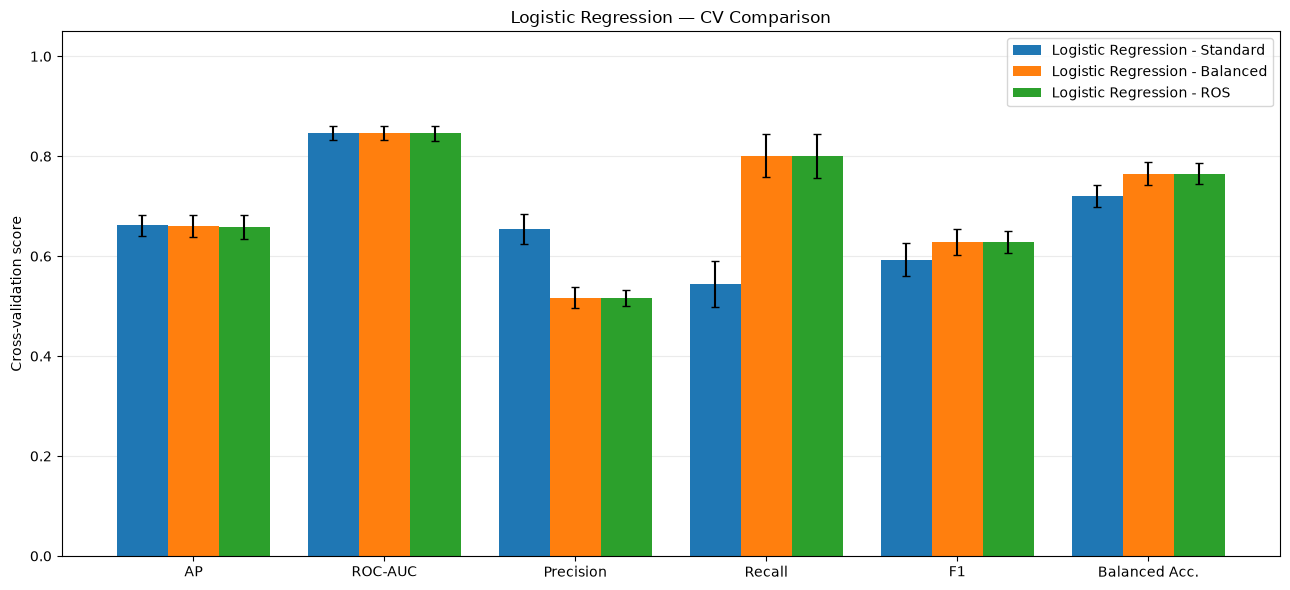

In [12]:
lr_all_results = pd.concat(
    [
        lr_standard_results,
        lr_balanced_results,
        lr_ros_results,
    ],
    ignore_index=True
)

lr_means, lr_stds = compare_models_cv(
    lr_all_results,
    title="Logistic Regression — CV Comparison",
    save_path=(
        project_root
        / "reports"
        / "figures"
        / "models"
        / "logistic_regression_cv_comparison.png"
    )
)


In [13]:

lr_best_name = lr_means["average_precision"].idxmax()

lr_best_results = lr_all_results[
    lr_all_results["model"] == lr_best_name
].copy()

lr_pipelines = {
    "Logistic Regression - Standard": lr_standard,
    "Logistic Regression - Balanced": lr_balanced,
    "Logistic Regression - ROS": lr_ros,
}

lr_best_pipeline = lr_pipelines[lr_best_name]

print("Selected:", lr_best_name)
print(
    "Mean AP:",
    round(lr_best_results["average_precision"].mean(), 4)
)


Selected: Logistic Regression - Standard
Mean AP: 0.6615



#### Key Findings

**1. Ranking Performance**
- Standard Logistic Regression achieves the highest Average Precision (0.6615) and ROC-AUC (0.8462).
- Balanced and ROS configurations achieve nearly identical ranking performance.
- The differences in Average Precision are very small (less than 0.003), providing no strong evidence that one configuration ranks churners substantially better.

**2. Impact of Class Imbalance Handling**
- Standard Logistic Regression achieves the highest Precision (0.6538) but the lowest Recall (0.5438).
- Class weighting increases Recall to 0.8013, while Precision decreases to 0.5167.
- ROS produces nearly identical results to class weighting, with Recall of 0.8013 and Precision of 0.5163.
- Balanced Logistic Regression achieves the highest F1-score (0.6281) and Balanced Accuracy (0.7653).

**3. Cross-Validation Stability**
- Average Precision and ROC-AUC exhibit relatively low standard deviations across the five folds.
- All three configurations demonstrate reasonably consistent ranking performance.

**4. Computational Efficiency**
- Standard and Balanced Logistic Regression have relatively low training times.
- ROS requires additional training time due to oversampling.
- ROS does not provide a meaningful predictive improvement over class weighting.

#### Conclusion

Standard Logistic Regression achieves the highest mean Average Precision, the primary benchmark metric.

However, class weighting and ROS substantially improve recall at the default classification threshold, at the expense of precision.

Since the three configurations achieve nearly identical ranking performance, no definitive superiority can be established at this stage.

Standard Logistic Regression remains the leading configuration by Average Precision, while Balanced Logistic Regression offers a more favorable recall-oriented trade-off.


## 2. Random Forest

The main objectives are:
- Evaluate Random Forest for customer churn prediction.
- Investigate the impact of class weighting on model performance.
- Compare ranking performance and classification metrics.
- Select the best configuration based primarily on Average Precision.

Two configurations are evaluated:
- **Standard:** Random Forest without class weighting or resampling.
- **Balanced:** Random Forest using `class_weight="balanced"` to address class imbalance.

Both configurations use the same stratified 5-fold cross-validation protocol.

Numerical features are not standardized, since tree-based models do not require feature scaling.

### 2.1 Standard Random Forest

The standard configuration serves as the baseline for evaluating Random Forest without class imbalance handling.

**Model configuration:**
- Number of trees: 200.
- Maximum tree depth: None (unrestricted).
- Class weighting: None.
- Random state: 42.
- Parallel processing: All available CPU cores.

The objective is to establish a reference for evaluating whether class weighting improves minority-class detection and overall predictive performance.


In [14]:
# Preprocessing for tree-based models
preprocessor_tree = build_preprocessor(
    numeric_features=numeric_features,
    categorical_features=categorical_features,
    binary_features=binary_features,
    scale_numeric=False
)

# Standard Random Forest
rf_standard = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("model", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

rf_standard


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature

In [15]:

rf_standard_results = evaluate_model_cv(
    model=rf_standard,
    X=X_train,
    y=y_train,
    cv=cv,
    model_name="Random Forest - Standard"
)

display(rf_standard_results.round(4))


,model,fold,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,fit_time,prediction_time
0,Random Forest - Standard,1,0.5745,0.8167,0.5935,0.4883,0.5358,0.6838,0.8763,0.1896
1,Random Forest - Standard,2,0.5933,0.8070,0.6063,0.4482,0.5154,0.6715,0.8378,0.0760
2,Random Forest - Standard,3,0.6460,0.8271,0.6504,0.5351,0.5872,0.7156,0.6152,0.0839
3,Random Forest - Standard,4,0.6098,0.8134,0.6109,0.4883,0.5428,0.6880,0.6208,0.0777
4,Random Forest - Standard,5,0.6487,0.8418,0.6682,0.4849,0.5620,0.6989,0.7495,0.1587


In [16]:

rf_standard_summary = (
    rf_standard_results[metric_columns]
    .agg(["mean", "std"])
    .T
)

display(rf_standard_summary.round(4))


,mean,std
average_precision,0.6145,0.0325
roc_auc,0.8212,0.0136
precision,0.6259,0.0318
recall,0.4890,0.0309
f1,0.5486,0.0272
balanced_accuracy,0.6916,0.0166
fit_time,0.7399,0.1205
prediction_time,0.1172,0.0532



#### Results and Interpretation

Standard Random Forest achieves the following mean cross-validation performance:

- **Average Precision:** 0.6145 ± 0.0325
- **ROC-AUC:** 0.8212 ± 0.0136
- **Precision:** 0.6259
- **Recall:** 0.4890
- **F1-score:** 0.5486
- **Balanced Accuracy:** 0.6916

**Key findings:**

- The model demonstrates reasonable ranking performance, achieving an Average Precision of 0.6145.
- Precision reaches 62.59%, while recall remains relatively low at 48.90%.
- At the default classification threshold, more than half of actual churners are not identified.
- Average Precision varies moderately across folds, with a standard deviation of 0.0325.
- Training takes approximately 1 second per fold on average, while prediction time exhibits some variability.

**Conclusion:**

Standard Random Forest provides a useful baseline for the tree-based model family.

However, its relatively low recall suggests that the default configuration may not adequately identify customers at risk of churn.

The next experiment evaluates whether class weighting improves churn detection while maintaining ranking performance.



### 2.2 Balanced Random Forest

This experiment evaluates Random Forest with balanced class weights to address class imbalance.

The `class_weight="balanced"` parameter automatically assigns weights inversely proportional to class frequencies.

The configuration retains the same hyperparameters as Standard Random Forest:
- 200 decision trees.
- Default tree depth and splitting parameters.
- Balanced class weights.
- No resampling.
- Identical preprocessing and stratified 5-fold cross-validation.


In [17]:

rf_balanced = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("model", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_balanced


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature

In [18]:

rf_balanced_results = evaluate_model_cv(
    model=rf_balanced,
    X=X_train,
    y=y_train,
    cv=cv,
    model_name="Random Forest - Balanced"
)

display(rf_balanced_results.round(4))


,model,fold,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,fit_time,prediction_time
0,Random Forest - Balanced,1,0.5644,0.8184,0.5593,0.6622,0.6064,0.7369,0.9116,0.2364
1,Random Forest - Balanced,2,0.5826,0.8095,0.5366,0.5886,0.5614,0.7025,0.8389,0.0917
2,Random Forest - Balanced,3,0.6371,0.8274,0.5651,0.6823,0.6182,0.7463,0.7182,0.0924
3,Random Forest - Balanced,4,0.6072,0.8162,0.5706,0.6622,0.6130,0.7411,0.6788,0.1151
4,Random Forest - Balanced,5,0.6349,0.8424,0.5761,0.6455,0.6088,0.7369,0.8245,0.1180


In [19]:

rf_balanced_summary = (
    rf_balanced_results[metric_columns]
    .agg(["mean", "std"])
    .T
)

display(rf_balanced_summary.round(4))


,mean,std
average_precision,0.6052,0.0320
roc_auc,0.8228,0.0127
precision,0.5615,0.0153
recall,0.6482,0.0357
f1,0.6016,0.0229
balanced_accuracy,0.7328,0.0173
fit_time,0.7944,0.0946
prediction_time,0.1307,0.0603



#### Results and Interpretation

Balanced Random Forest achieves the following mean cross-validation performance:

- **Average Precision:** 0.6052 ± 0.0320
- **ROC-AUC:** 0.8228 ± 0.0127
- **Precision:** 0.5615
- **Recall:** 0.6482
- **F1-score:** 0.6016
- **Balanced Accuracy:** 0.7328

**Key findings:**

- Class weighting improves recall from 48.90% to 64.82% compared with Standard Random Forest.
- Precision decreases from 62.59% to 56.15%, indicating a trade-off between detecting more churners and generating false-positive predictions.
- F1-score and Balanced Accuracy improve with class weighting.
- Average Precision decreases slightly from 0.6145 to 0.6052.
- Ranking performance remains relatively stable across folds, with an Average Precision standard deviation of 0.0320.
- Class weighting slightly increases mean training time.

**Conclusion:**

Balanced Random Forest improves churn detection at the default classification threshold but does not improve Average Precision.

The results suggest that class weighting primarily changes classification behavior rather than providing better ranking performance.

Both configurations will now be compared to select the representative Random Forest model.



### 2.3 Random Forest — Model Comparison

The two Random Forest configurations are compared using mean cross-validation scores, standard deviations, and computational efficiency.


Random Forest — CV Comparison


,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,fit_time,prediction_time
model,,,,,,,,
Random Forest - Standard,0.6145 ± 0.0325,0.8212 ± 0.0136,0.6259 ± 0.0318,0.4890 ± 0.0309,0.5486 ± 0.0272,0.6916 ± 0.0166,0.7399 ± 0.1205,0.1172 ± 0.0532
Random Forest - Balanced,0.6052 ± 0.0320,0.8228 ± 0.0127,0.5615 ± 0.0153,0.6482 ± 0.0357,0.6016 ± 0.0229,0.7328 ± 0.0173,0.7944 ± 0.0946,0.1307 ± 0.0603


Figure saved to: C:\Users\Lenovo\Desktop\DS\Customer_Churn\Teleco_Customer_Churn\reports\figures\models\random_forest_cv_comparison.png


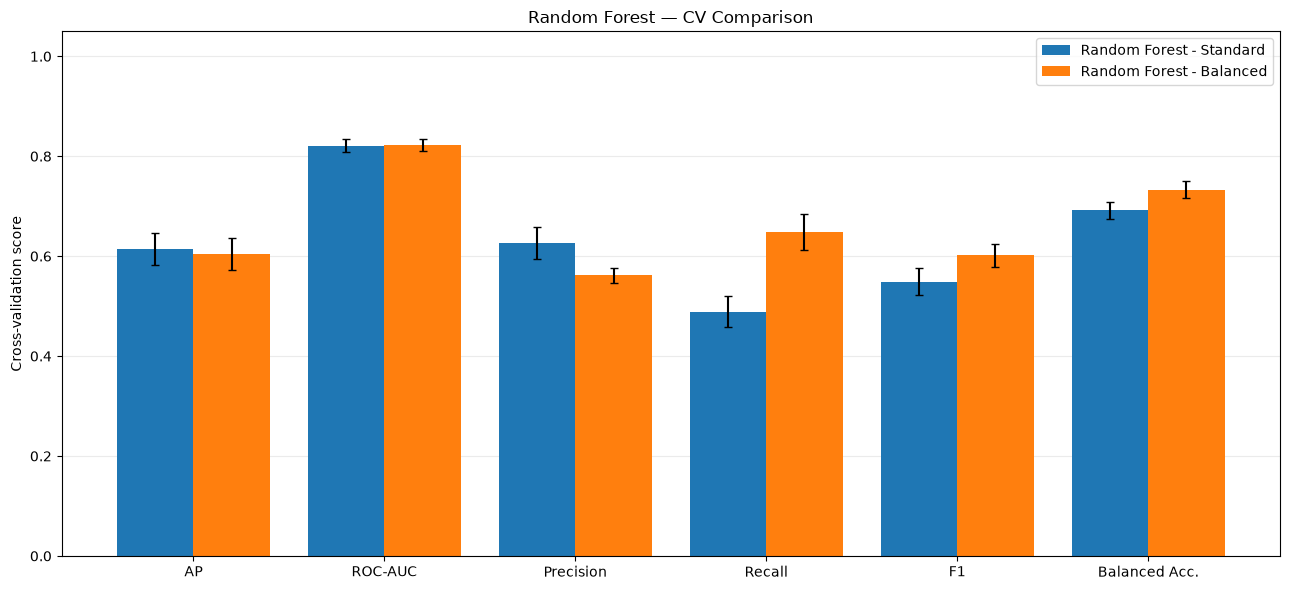

In [20]:

# Combine Random Forest results
rf_all_results = pd.concat(
    [
        rf_standard_results,
        rf_balanced_results
    ],
    ignore_index=True
)

# Compare and export
rf_means, rf_stds = compare_models_cv(
    rf_all_results,
    title="Random Forest — CV Comparison",
    save_path=(
        project_root
        / "reports"
        / "figures"
        / "models"
        / "random_forest_cv_comparison.png"
    )
)


In [21]:

rf_best_name = rf_means["average_precision"].idxmax()

rf_best_results = rf_all_results[
    rf_all_results["model"] == rf_best_name
].copy()

rf_pipelines = {
    "Random Forest - Standard": rf_standard,
    "Random Forest - Balanced": rf_balanced,
}

rf_best_pipeline = rf_pipelines[rf_best_name]

print("Selected:", rf_best_name)
print(
    "Mean AP:",
    round(rf_best_results["average_precision"].mean(), 4)
)


Selected: Random Forest - Standard
Mean AP: 0.6145



## 3. Gradient Boosting
Two configurations are evaluated:
- **Standard:** No class weighting or resampling.
- **ROS:** Random oversampling applied to training folds only.

Both configurations use the same stratified 5-fold cross-validation protocol.

### 3.1 Standard Gradient Boosting

This experiment evaluates Gradient Boosting without class imbalance handling.

**Configuration:**
- 100 boosting stages.
- Learning rate of 0.1.
- Maximum tree depth of 3.
- No resampling.
- Same tree-based preprocessing pipeline.



In [22]:


gb_standard = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("model", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

gb_standard


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature

In [23]:

gb_standard_results = evaluate_model_cv(
    model=gb_standard,
    X=X_train,
    y=y_train,
    cv=cv,
    model_name="Gradient Boosting - Standard"
)

display(gb_standard_results.round(4))


,model,fold,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,fit_time,prediction_time
0,Gradient Boosting - Standard,1,0.6495,0.8407,0.6509,0.5050,0.5687,0.7036,2.0657,0.0318
1,Gradient Boosting - Standard,2,0.6337,0.8298,0.6118,0.4849,0.5410,0.6869,1.6844,0.0214
2,Gradient Boosting - Standard,3,0.6930,0.8453,0.6627,0.5652,0.6101,0.7307,1.3610,0.0207
3,Gradient Boosting - Standard,4,0.6838,0.8619,0.6653,0.5452,0.5993,0.7231,1.4334,0.0219
4,Gradient Boosting - Standard,5,0.6806,0.8627,0.7193,0.5485,0.6224,0.7356,1.3939,0.0143


In [24]:

gb_standard_summary = (
    gb_standard_results[metric_columns]
    .agg(["mean", "std"])
    .T
)

display(gb_standard_summary.round(4))


,mean,std
average_precision,0.6681,0.0252
roc_auc,0.8481,0.0142
precision,0.6620,0.0385
recall,0.5298,0.0334
f1,0.5883,0.0331
balanced_accuracy,0.7160,0.0203
fit_time,1.5877,0.2960
prediction_time,0.0220,0.0063



#### Results and Interpretation

Standard Gradient Boosting achieves the following mean cross-validation performance:

- **Average Precision:** 0.6681 ± 0.0252
- **ROC-AUC:** 0.8481 ± 0.0142
- **Precision:** 0.6620
- **Recall:** 0.5298
- **F1-score:** 0.5883
- **Balanced Accuracy:** 0.7160

**Key findings:**

- The model demonstrates good ranking performance, achieving an Average Precision of 0.6681.
- ROC-AUC reaches 0.8481, indicating good discrimination between churners and non-churners.
- Precision is relatively high (66.20%), while recall remains limited (52.98%) at the default classification threshold.
- Approximately 47% of actual churners are not detected.
- Average Precision shows relatively moderate variability across folds, with a standard deviation of 0.0252.
- Mean training time is approximately 2.05 seconds per fold.



### 3.2 Gradient Boosting with RandomOverSampler

This experiment evaluates Gradient Boosting with RandomOverSampler (ROS) to address class imbalance.

To prevent data leakage:
- Oversampling is performed only within the training portion of each cross-validation fold.
- Validation folds retain their original class distribution.
- Preprocessing, resampling, and model training are integrated into an `imblearn` Pipeline.

The model uses the same hyperparameters as Standard Gradient Boosting to isolate the effect of oversampling.

The objective is to evaluate whether ROS improves recall and balanced accuracy while preserving Average Precision.


In [25]:
gb_ros = ImbPipeline([
    ("preprocessor", preprocessor_tree),
    ("sampler", RandomOverSampler(
        random_state=42
    )),
    ("model", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

gb_ros


,steps,"[('preprocessor', ...), ('sampler', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"tran

In [26]:

gb_ros_results = evaluate_model_cv(
    model=gb_ros,
    X=X_train,
    y=y_train,
    cv=cv,
    model_name="Gradient Boosting - ROS"
)

display(gb_ros_results.round(4))


,model,fold,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,fit_time,prediction_time
0,Gradient Boosting - ROS,1,0.6485,0.8406,0.5281,0.7860,0.6317,0.7662,1.5936,0.0149
1,Gradient Boosting - ROS,2,0.6345,0.8299,0.5184,0.7525,0.6139,0.7500,1.6298,0.0162
2,Gradient Boosting - ROS,3,0.6860,0.8431,0.5201,0.7793,0.6238,0.7598,1.4969,0.0136
3,Gradient Boosting - ROS,4,0.6773,0.8604,0.5434,0.8161,0.6524,0.7842,1.5154,0.0130
4,Gradient Boosting - ROS,5,0.6734,0.8568,0.5485,0.7759,0.6427,0.7725,1.4669,0.0157


In [27]:

gb_ros_summary = (
    gb_ros_results[metric_columns]
    .agg(["mean", "std"])
    .T
)

display(gb_ros_summary.round(4))


,mean,std
average_precision,0.6639,0.0216
roc_auc,0.8462,0.0124
precision,0.5317,0.0136
recall,0.7819,0.0229
f1,0.6329,0.0152
balanced_accuracy,0.7665,0.0129
fit_time,1.5405,0.0685
prediction_time,0.0147,0.0014



#### Results and Interpretation

Gradient Boosting with RandomOverSampler achieves the following mean cross-validation performance:

- **Average Precision:** 0.6639 ± 0.0216
- **ROC-AUC:** 0.8462 ± 0.0124
- **Precision:** 0.5317
- **Recall:** 0.7819
- **F1-score:** 0.6329
- **Balanced Accuracy:** 0.7665

**Key findings:**

- ROS achieves an Average Precision of 0.6639, indicating good ranking performance.
- Recall reaches 78.19%, substantially improving minority-class detection compared with Standard Gradient Boosting.
- Precision decreases to 53.17%, reflecting an increase in false-positive predictions relative to predicted positives.
- F1-score and Balanced Accuracy improve compared with the standard configuration.
- Average Precision shows relatively low variability across folds (std = 0.0216).
- Mean training time increases to approximately 2.53 seconds per fold.




### 3.3 Gradient Boosting — Model Comparison

The Standard and ROS configurations are compared using the same stratified 5-fold cross-validation protocol.

The comparison evaluates ranking performance, classification metrics, cross-validation stability, and computational efficiency.

Average Precision is used as the primary selection criterion.



Gradient Boosting — CV Comparison


,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,fit_time,prediction_time
model,,,,,,,,
Gradient Boosting - Standard,0.6681 ± 0.0252,0.8481 ± 0.0142,0.6620 ± 0.0385,0.5298 ± 0.0334,0.5883 ± 0.0331,0.7160 ± 0.0203,1.5877 ± 0.2960,0.0220 ± 0.0063
Gradient Boosting - ROS,0.6639 ± 0.0216,0.8462 ± 0.0124,0.5317 ± 0.0136,0.7819 ± 0.0229,0.6329 ± 0.0152,0.7665 ± 0.0129,1.5405 ± 0.0685,0.0147 ± 0.0014


Figure saved to: C:\Users\Lenovo\Desktop\DS\Customer_Churn\Teleco_Customer_Churn\reports\figures\models\gradient_boosting_cv_comparison.png


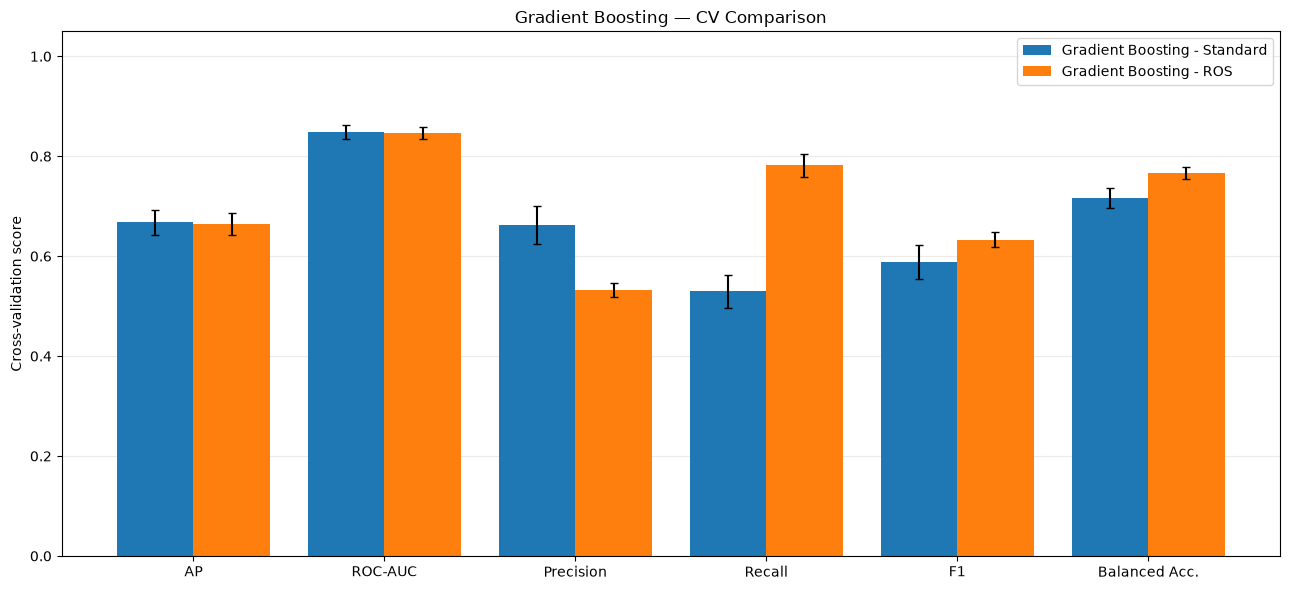

In [28]:

# Combine Gradient Boosting results
gb_all_results = pd.concat(
    [
        gb_standard_results,
        gb_ros_results
    ],
    ignore_index=True
)

# Compare configurations and export figure
gb_means, gb_stds = compare_models_cv(
    gb_all_results,
    title="Gradient Boosting — CV Comparison",
    save_path=(
        project_root
        / "reports"
        / "figures"
        / "models"
        / "gradient_boosting_cv_comparison.png"
    )
)



#### Key Findings

**1. Ranking Performance**
- Standard Gradient Boosting achieves the highest mean Average Precision (0.6681), compared with 0.6639 for ROS.
- Standard also achieves a slightly higher ROC-AUC (0.8481 versus 0.8462).
- Both configurations demonstrate similar ranking performance, with small differences relative to cross-validation variability.
- ROS exhibits a slightly lower Average Precision standard deviation (0.0216 versus 0.0252).

**2. Impact of Oversampling**
- ROS substantially increases recall from 52.98% to 78.19%.
- Precision decreases from 66.20% to 53.17%.
- F1-score improves from 0.5883 to 0.6329.
- Balanced Accuracy increases from 0.7160 to 0.7665.
- These changes indicate a more recall-oriented classification behavior at the default threshold.

**3. Computational Efficiency**
- Standard Gradient Boosting achieves a lower mean training time (2.05 seconds versus 2.53 seconds).
- ROS increases training cost due to the larger resampled training sets.
- Prediction times remain relatively low for both configurations.

#### Conclusion

Standard Gradient Boosting achieves the highest mean Average Precision, our primary benchmark metric.

Although ROS substantially improves recall, F1-score, and Balanced Accuracy at the default classification threshold, it does not improve ranking performance.

The small Average Precision difference does not establish statistically significant superiority.

**Selected configuration: Gradient Boosting — Standard**

This configuration is provisionally selected based on mean cross-validation Average Precision.

The classification threshold will be considered separately during the subsequent optimization stages.


In [29]:

gb_best_name = gb_means["average_precision"].idxmax()

gb_best_results = gb_all_results[
    gb_all_results["model"] == gb_best_name
].copy()

gb_best_pipeline = (
    gb_standard
    if gb_best_name == "Gradient Boosting - Standard"
    else gb_ros
)

print("Selected:", gb_best_name)
print(
    "Mean AP:",
    round(gb_best_results["average_precision"].mean(), 4)
)


Selected: Gradient Boosting - Standard
Mean AP: 0.6681



## 4. XGBoost

Three configurations are evaluated:
- **Standard:** No class imbalance handling.
- **Weighted:** Positive-class weighting using `scale_pos_weight`.
- **ROS:** RandomOverSampler applied within training folds only.

All configurations are evaluated using the same stratified 5-fold cross-validation protocol.

### 4.1 Standard XGBoost

The standard configuration establishes a baseline without class weighting or resampling.

**Model configuration:**
- Number of boosting rounds: 200.
- Learning rate: 0.05.
- Maximum tree depth: 3.
- Row subsampling: 0.8.
- Column subsampling: 0.8.
- Tree method: histogram-based.
- Objective: binary logistic classification.
- No class weighting or resampling.

The objective is to evaluate the predictive performance of XGBoost before introducing class imbalance handling strategies.


In [30]:


xgb_standard = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("model", XGBClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    ))
])

xgb_standard


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature

In [31]:

xgb_standard_results = evaluate_model_cv(
    model=xgb_standard,
    X=X_train,
    y=y_train,
    cv=cv,
    model_name="XGBoost - Standard"
)

display(xgb_standard_results.round(4))


,model,fold,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,fit_time,prediction_time
0,XGBoost - Standard,1,0.6589,0.8431,0.6368,0.4983,0.5591,0.6978,0.3571,0.0313
1,XGBoost - Standard,2,0.6415,0.8326,0.6332,0.4849,0.5492,0.6918,0.5117,0.0252
2,XGBoost - Standard,3,0.6943,0.8446,0.6735,0.5518,0.6066,0.7276,0.5123,0.0312
3,XGBoost - Standard,4,0.6843,0.8622,0.6653,0.5585,0.6073,0.7285,0.3722,0.0246
4,XGBoost - Standard,5,0.6776,0.8586,0.7136,0.5251,0.6050,0.7245,0.3624,0.0271


In [32]:

xgb_standard_summary = (
    xgb_standard_results[metric_columns]
    .agg(["mean", "std"])
    .T
)

display(xgb_standard_summary.round(4))


,mean,std
average_precision,0.6713,0.0211
roc_auc,0.8482,0.0121
precision,0.6645,0.0326
recall,0.5237,0.0322
f1,0.5854,0.0288
balanced_accuracy,0.7140,0.0178
fit_time,0.4231,0.0813
prediction_time,0.0279,0.0032



#### Results and Interpretation

Standard XGBoost achieves the following mean cross-validation performance:

- **Average Precision:** 0.6713 ± 0.0211
- **ROC-AUC:** 0.8482 ± 0.0121
- **Precision:** 0.6645
- **Recall:** 0.5237
- **F1-score:** 0.5854
- **Balanced Accuracy:** 0.7140

**Key findings:**

- The model demonstrates good ranking performance, achieving an Average Precision of 0.6713.
- ROC-AUC reaches 0.8482, indicating good discrimination between churners and non-churners.
- Precision is relatively high (66.45%), while recall remains limited (52.37%).
- At the default classification threshold, approximately 48% of actual churners are not detected.
- Average Precision exhibits relatively low variability across folds (std = 0.0211).
- Mean training time is approximately 0.85 seconds per fold, although execution times vary.


### 4.2 Weighted XGBoost

This experiment evaluates XGBoost with positive-class weighting to address class imbalance.

Unlike RandomOverSampler, class weighting does not duplicate observations. Instead, it increases the contribution of positive-class observations during training.

The `scale_pos_weight` parameter is calculated as:

`scale_pos_weight = n_negative / n_positive`

To prevent data leakage, the class ratio is recalculated using only the training observations of each cross-validation fold.

All other hyperparameters remain identical to Standard XGBoost.

The objective is to determine whether positive-class weighting improves recall and balanced accuracy while preserving ranking performance.


In [33]:

n_negative = (y_train == 0).sum()
n_positive = (y_train == 1).sum()

scale_pos_weight = n_negative / n_positive

print("Negative samples:", n_negative)
print("Positive samples:", n_positive)
print("Scale pos weight:", round(scale_pos_weight, 4))


Negative samples: 4139
Positive samples: 1495
Scale pos weight: 2.7686


In [34]:

xgb_weighted = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("model", XGBClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        scale_pos_weight=scale_pos_weight,
        random_state=42,
        n_jobs=-1
    ))
])

xgb_weighted


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature

In [35]:

xgb_weighted_results = evaluate_model_cv(
    model=xgb_weighted,
    X=X_train,
    y=y_train,
    cv=cv,
    model_name="XGBoost - Weighted",
    fold_scale_pos_weight=True
)

display(xgb_weighted_results.round(4))


,model,fold,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,fit_time,prediction_time
0,XGBoost - Weighted,1,0.6582,0.8433,0.5247,0.8161,0.6387,0.7746,0.3599,0.0343
1,XGBoost - Weighted,2,0.6371,0.8310,0.5102,0.7525,0.6081,0.7458,0.3554,0.0274
2,XGBoost - Weighted,3,0.6896,0.8451,0.5084,0.8060,0.6235,0.7623,0.3731,0.0261
3,XGBoost - Weighted,4,0.6844,0.8631,0.5312,0.8261,0.6466,0.7814,0.3555,0.0248
4,XGBoost - Weighted,5,0.6765,0.8576,0.5356,0.8060,0.6435,0.7766,0.3332,0.0313


In [36]:

xgb_weighted_summary = (
    xgb_weighted_results[metric_columns]
    .agg(["mean", "std"])
    .T
)

display(xgb_weighted_summary.round(4))


,mean,std
average_precision,0.6692,0.0215
roc_auc,0.8480,0.0127
precision,0.5220,0.0122
recall,0.8013,0.0285
f1,0.6321,0.0161
balanced_accuracy,0.7682,0.0143
fit_time,0.3554,0.0144
prediction_time,0.0288,0.0039



#### Results and Interpretation

Weighted XGBoost achieves the following mean cross-validation performance:

- **Average Precision:** 0.6692 ± 0.0215
- **ROC-AUC:** 0.8480 ± 0.0127
- **Precision:** 0.5220
- **Recall:** 0.8013
- **F1-score:** 0.6321
- **Balanced Accuracy:** 0.7682

**Key findings:**

- Positive-class weighting substantially improves recall from 52.37% to 80.13% compared with Standard XGBoost.
- Precision decreases from 66.45% to 52.20%, reflecting a higher proportion of false-positive predictions.
- F1-score increases from 0.5854 to 0.6321, while Balanced Accuracy improves from 0.7140 to 0.7682.
- Average Precision remains nearly unchanged (0.6692 versus 0.6713), indicating similar ranking performance.
- Cross-validation performance remains reasonably stable, with an Average Precision standard deviation of 0.0215.
- Training times exhibit some variability across folds.



### 4.3 XGBoost with RandomOverSampler

This experiment evaluates XGBoost with RandomOverSampler (ROS) as an alternative strategy for handling class imbalance.

Unlike `scale_pos_weight`, which adjusts the contribution of positive-class observations during training, ROS balances the class distribution by randomly duplicating minority-class samples.

To prevent data leakage:
- ROS is applied exclusively to the training portion of each cross-validation fold.
- Validation folds retain their original class distribution.
- Preprocessing and oversampling are integrated into an `imblearn` Pipeline.

The same XGBoost hyperparameters are used across all three configurations.

The objective is to evaluate whether ROS improves Average Precision, recall, F1-score, and Balanced Accuracy compared with Standard and Weighted XGBoost.


In [37]:



xgb_ros = ImbPipeline([
    ("preprocessor", preprocessor_tree),
    ("sampler", RandomOverSampler(
        random_state=42
    )),
    ("model", XGBClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    ))
])

xgb_ros


,steps,"[('preprocessor', ...), ('sampler', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"tran

In [38]:

xgb_ros_results = evaluate_model_cv(
    model=xgb_ros,
    X=X_train,
    y=y_train,
    cv=cv,
    model_name="XGBoost - ROS"
)

display(xgb_ros_results.round(4))


,model,fold,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,fit_time,prediction_time
0,XGBoost - ROS,1,0.6469,0.8411,0.5288,0.7993,0.6365,0.7710,0.4338,0.0292
1,XGBoost - ROS,2,0.6332,0.8280,0.5091,0.7492,0.6062,0.7441,0.5935,0.0378
2,XGBoost - ROS,3,0.6893,0.8450,0.5161,0.8027,0.6283,0.7655,0.3976,0.0254
3,XGBoost - ROS,4,0.6805,0.8624,0.5356,0.8294,0.6509,0.7849,0.4123,0.0269
4,XGBoost - ROS,5,0.6831,0.8583,0.5558,0.8161,0.6612,0.7901,0.4348,0.0292


In [39]:

xgb_ros_summary = (
    xgb_ros_results[metric_columns]
    .agg(["mean", "std"])
    .T
)

display(xgb_ros_summary.round(4))


,mean,std
average_precision,0.6666,0.0249
roc_auc,0.8470,0.0138
precision,0.5291,0.0182
recall,0.7993,0.0305
f1,0.6366,0.0212
balanced_accuracy,0.7711,0.0181
fit_time,0.4544,0.0793
prediction_time,0.0297,0.0048



#### Results and Interpretation

XGBoost with RandomOverSampler achieves the following mean cross-validation performance:

- **Average Precision:** 0.6666 ± 0.0249
- **ROC-AUC:** 0.8470 ± 0.0138
- **Precision:** 0.5291
- **Recall:** 0.7993
- **F1-score:** 0.6366
- **Balanced Accuracy:** 0.7711

**Key findings:**

- ROS achieves good ranking performance, with an Average Precision of 0.6666.
- Recall reaches 79.93%, substantially improving minority-class detection compared with Standard XGBoost.
- Precision decreases to 52.91%, indicating a higher proportion of false-positive predictions.
- F1-score and Balanced Accuracy improve compared with the standard configuration.
- Average Precision exhibits moderate variability across folds (std = 0.0249).
- Mean training time increases to approximately 1.40 seconds per fold.



### 4.4 XGBoost — Model Comparison

The three XGBoost configurations are compared using the same stratified 5-fold cross-validation protocol.

The comparison considers ranking performance, classification metrics, cross-validation stability, and computational efficiency.

Average Precision remains the primary criterion for selecting the representative configuration.



XGBoost — CV Comparison


,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,fit_time,prediction_time
model,,,,,,,,
XGBoost - Standard,0.6713 ± 0.0211,0.8482 ± 0.0121,0.6645 ± 0.0326,0.5237 ± 0.0322,0.5854 ± 0.0288,0.7140 ± 0.0178,0.4231 ± 0.0813,0.0279 ± 0.0032
XGBoost - Weighted,0.6692 ± 0.0215,0.8480 ± 0.0127,0.5220 ± 0.0122,0.8013 ± 0.0285,0.6321 ± 0.0161,0.7682 ± 0.0143,0.3554 ± 0.0144,0.0288 ± 0.0039
XGBoost - ROS,0.6666 ± 0.0249,0.8470 ± 0.0138,0.5291 ± 0.0182,0.7993 ± 0.0305,0.6366 ± 0.0212,0.7711 ± 0.0181,0.4544 ± 0.0793,0.0297 ± 0.0048


Figure saved to: C:\Users\Lenovo\Desktop\DS\Customer_Churn\Teleco_Customer_Churn\reports\figures\models\xgboost_cv_comparison.png


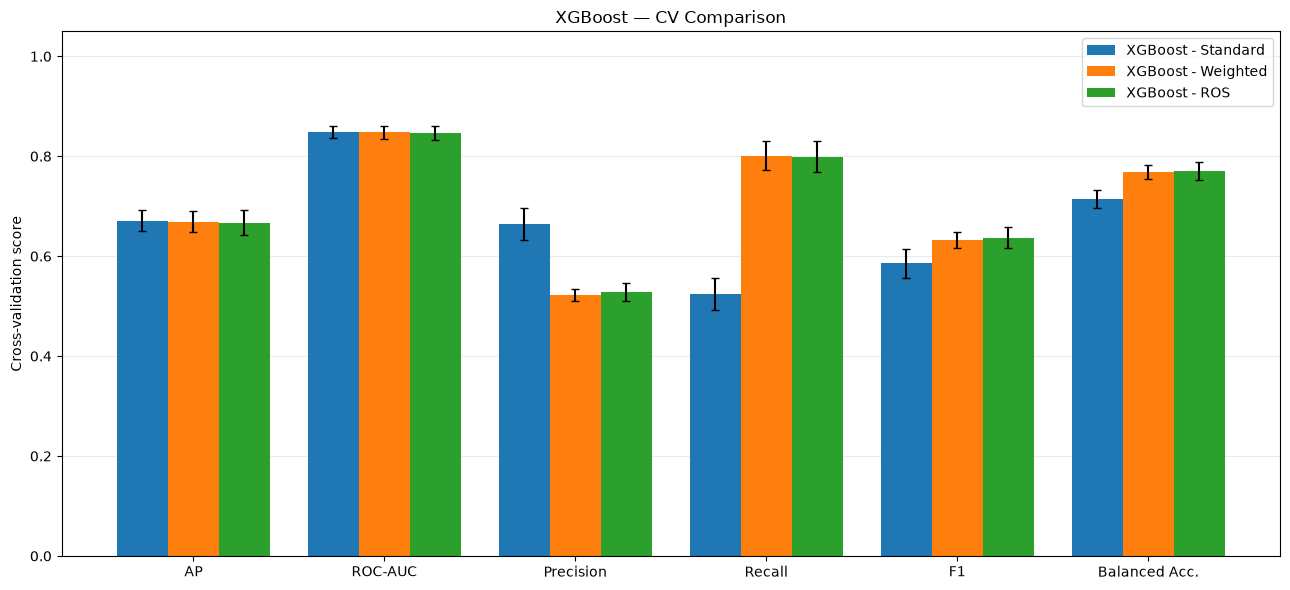

In [40]:

# Combine XGBoost results
xgb_all_results = pd.concat(
    [
        xgb_standard_results,
        xgb_weighted_results,
        xgb_ros_results
    ],
    ignore_index=True
)

# Compare and export
xgb_means, xgb_stds = compare_models_cv(
    xgb_all_results,
    title="XGBoost — CV Comparison",
    save_path=(
        project_root
        / "reports"
        / "figures"
        / "models"
        / "xgboost_cv_comparison.png"
    )
)



#### Key Findings

**1. Ranking Performance**

- Standard XGBoost achieves the highest mean Average Precision (0.6713), followed by Weighted (0.6692) and ROS (0.6666).
- ROC-AUC remains nearly identical across configurations, ranging from 0.8470 to 0.8482.
- Differences in Average Precision are small relative to cross-validation variability.
- All configurations demonstrate reasonably consistent ranking performance across folds.

**2. Impact of Class Imbalance Handling**

- Standard XGBoost achieves the highest precision (66.45%) but the lowest recall (52.37%).
- Positive-class weighting increases recall to 80.13%, while precision decreases to 52.20%.
- ROS achieves similar recall (79.93%) with slightly higher precision (52.91%).
- ROS achieves the highest F1-score (0.6366) and Balanced Accuracy (0.7711).
- Neither class weighting nor ROS improves Average Precision over the standard configuration.

**3. Computational Efficiency**

- Standard XGBoost achieves the lowest mean training time (0.85 seconds per fold).
- Weighted XGBoost requires approximately 1.05 seconds per fold.
- ROS increases mean training time to approximately 1.40 seconds due to oversampling.

#### Conclusion

Standard XGBoost achieves the highest mean Average Precision, our primary selection metric.

Although Weighted and ROS configurations improve recall, F1-score, and Balanced Accuracy at the default classification threshold, they do not improve ranking performance.

The small differences in Average Precision do not establish statistically significant superiority.

**Selected configuration: XGBoost — Standard**

This configuration is provisionally selected to represent XGBoost in the final comparison between model families.

Classification threshold optimization will be addressed separately in subsequent stages.


In [41]:

xgb_best_name = xgb_means["average_precision"].idxmax()

xgb_best_results = xgb_all_results[
    xgb_all_results["model"] == xgb_best_name
].copy()

xgb_pipelines = {
    "XGBoost - Standard": xgb_standard,
    "XGBoost - Weighted": xgb_weighted,
    "XGBoost - ROS": xgb_ros,
}

xgb_best_pipeline = xgb_pipelines[xgb_best_name]

print("Selected:", xgb_best_name)
print(
    "Mean AP:",
    round(xgb_best_results["average_precision"].mean(), 4)
)


Selected: XGBoost - Standard
Mean AP: 0.6713



## 5. Final Model Comparison

After evaluating 10 model configurations across four algorithm families, the best configuration from each family was selected based on mean cross-validation Average Precision.

The selected models are:
- Logistic Regression — Standard
- Random Forest — Standard
- Gradient Boosting — Standard
- XGBoost — Standard

This section compares the four selected models using the same stratified 5-fold cross-validation protocol.

**Selection criteria:**
- Average Precision (primary metric).
- ROC-AUC and classification metrics.
- Stability across cross-validation folds.
- Training and prediction efficiency.

The objective is to identify the most promising candidates for hyperparameter optimization using Optuna and experiment tracking with MLflow.

The held-out test set remains untouched.



Best Models — CV Comparison


,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,fit_time,prediction_time
model,,,,,,,,
XGBoost - Standard,0.6713 ± 0.0211,0.8482 ± 0.0121,0.6645 ± 0.0326,0.5237 ± 0.0322,0.5854 ± 0.0288,0.7140 ± 0.0178,0.4231 ± 0.0813,0.0279 ± 0.0032
Gradient Boosting - Standard,0.6681 ± 0.0252,0.8481 ± 0.0142,0.6620 ± 0.0385,0.5298 ± 0.0334,0.5883 ± 0.0331,0.7160 ± 0.0203,1.5877 ± 0.2960,0.0220 ± 0.0063
Logistic Regression - Standard,0.6615 ± 0.0217,0.8462 ± 0.0141,0.6538 ± 0.0302,0.5438 ± 0.0457,0.5931 ± 0.0333,0.7198 ± 0.0223,0.0796 ± 0.0250,0.0133 ± 0.0016
Random Forest - Standard,0.6145 ± 0.0325,0.8212 ± 0.0136,0.6259 ± 0.0318,0.4890 ± 0.0309,0.5486 ± 0.0272,0.6916 ± 0.0166,0.7399 ± 0.1205,0.1172 ± 0.0532


Figure saved to: C:\Users\Lenovo\Desktop\DS\Customer_Churn\Teleco_Customer_Churn\reports\figures\models\global_cv_comparison.png


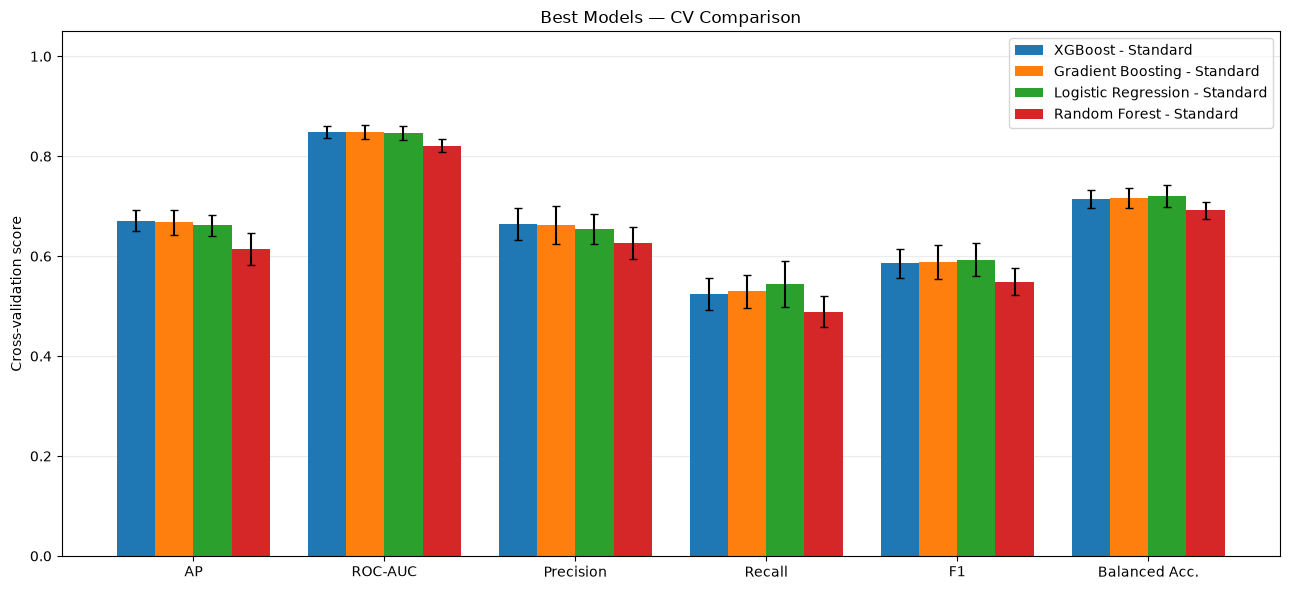

In [42]:

# Combine the best configuration from each model family
best_models_results = pd.concat(
    [
        lr_best_results,
        rf_best_results,
        gb_best_results,
        xgb_best_results
    ],
    ignore_index=True
)

# Final comparison
final_means, final_stds = compare_models_cv(
    best_models_results,
    title="Best Models — CV Comparison",
    save_path=(
        project_root
        / "reports"
        / "figures"
        / "models"
        / "global_cv_comparison.png"
    )
)


In [43]:

final_ranking = (
    final_means
    .sort_values(
        "average_precision",
        ascending=False
    )
)

display(final_ranking.round(4))


,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,fit_time,prediction_time
model,,,,,,,,
XGBoost - Standard,0.6713,0.8482,0.6645,0.5237,0.5854,0.7140,0.4231,0.0279
Gradient Boosting - Standard,0.6681,0.8481,0.6620,0.5298,0.5883,0.7160,1.5877,0.0220
Logistic Regression - Standard,0.6615,0.8462,0.6538,0.5438,0.5931,0.7198,0.0796,0.0133
Random Forest - Standard,0.6145,0.8212,0.6259,0.4890,0.5486,0.6916,0.7399,0.1172


In [44]:

# Select the top 2 candidates based on Average Precision
top_2_names = final_means.nlargest(
    2, "average_precision"
).index.tolist()

best_pipelines = {
    lr_best_name: lr_best_pipeline,
    rf_best_name: rf_best_pipeline,
    gb_best_name: gb_best_pipeline,
    xgb_best_name: xgb_best_pipeline
}

top_2_pipelines = {
    name: best_pipelines[name]
    for name in top_2_names
}

print("Selected candidates for Day 5:")

for rank, name in enumerate(top_2_names, start=1):
    print(
        f"{rank}. {name} | "
        f"AP = {final_means.loc[name, 'average_precision']:.4f}"
    )


Selected candidates for Day 5:
1. XGBoost - Standard | AP = 0.6713
2. Gradient Boosting - Standard | AP = 0.6681



## 6. Conclusion and Model Selection

### 6.1 Benchmark Summary

This notebook evaluated **10 model configurations across four classification algorithm families** using stratified 5-fold cross-validation.

The benchmark included:
- Logistic Regression: Standard, Balanced, ROS.
- Random Forest: Standard, Balanced.
- Gradient Boosting: Standard, ROS.
- XGBoost: Standard, Weighted, ROS.

All configurations were evaluated using consistent data splits, preprocessing pipelines, and evaluation metrics.

Average Precision (AP) was selected as the primary metric because customer churn prediction involves an imbalanced classification problem, where identifying and ranking customers at risk is more informative than accuracy alone.

### 6.2 Main Findings

**Ranking Performance**
- XGBoost Standard achieves the highest mean Average Precision (0.6713).
- Gradient Boosting Standard follows closely (0.6681).
- Logistic Regression Standard also demonstrates competitive performance (0.6615).
- Random Forest Standard achieves a lower Average Precision (0.6145).

The differences between the three leading models are small relative to cross-validation variability. Therefore, the benchmark does not establish statistically significant superiority.

**Class Imbalance Strategies**
- Class weighting and RandomOverSampler consistently improve recall at the default classification threshold of 0.5.
- These improvements generally come at the expense of precision.
- Neither strategy improves Average Precision over the corresponding standard configuration in the evaluated experiments.
- Standard configurations achieve the highest mean Average Precision within all four model families.

**Computational Efficiency and Stability**
- Logistic Regression provides an efficient baseline with relatively low training costs.
- XGBoost and Gradient Boosting demonstrate competitive ranking performance.
- Cross-validation scores show relatively moderate variability across folds.
- Execution times vary and should be interpreted as approximate measurements rather than definitive computational benchmarks.

### 6.3 Selected Models for Optimization

Based on mean cross-validation Average Precision, two candidates are selected for hyperparameter optimization:

1. **XGBoost — Standard:** AP = 0.6713 ± 0.0211.
2. **Gradient Boosting — Standard:** AP = 0.6681 ± 0.0252.

These models are selected as promising candidates rather than definitive winners.

Logistic Regression remains a useful baseline due to its simplicity, computational efficiency, and interpretability.

### 6.4 Limitations

- Hyperparameters were not optimized during this benchmark.
- Classification metrics were computed using the default threshold of 0.5, which may not provide the best operational trade-off.
- Differences between leading models are small and require cautious interpretation.
- Training and prediction times may be influenced by system-level variability.
- The held-out test set has not been used, preserving it for final evaluation.

### 6.5 Next Steps

The next stage focuses on optimizing the two selected models.

The planned workflow includes:
- Hyperparameter optimization using Optuna with TPE sampling.
- Stratified 5-fold cross-validation maximizing Average Precision.
- Experiment tracking with MLflow.
- Comparison of optimized models before final selection.
- Subsequent decision-threshold optimization to balance recall, precision, and business objectives.

The final test set remains untouched to provide an unbiased evaluation of the selected model at the end of the project.
